# Notebook 03: Sensor calibration with fewer temperature insertions

**Chip:** 3-axis MEMS accelerometer (axes X, Y, Z), in 3 range derivatives: ACC-2G (base), ACC-8G and ACC-16G.

**The problem:** an accelerometer's zero-g **offset** and **sensitivity** change with temperature. Today every die is tested at **3 temperatures** (−40, 25 and 85 °C), which means three handler insertions and about **7.2 s per die**. Each temperature coefficient is then fused into OTP.

**The AI idea:** test **only at 25 °C**, and predict how the die will behave at −40 and 85 °C from its 25 °C data plus process data. A small sample of dies (20%, `characterized_3temp`) still gets the full 3-temperature test; those dies are the training data.

**Dataset:** `sensor_calibration.csv`, with 11,060 dies.

| Task | Question | Method |
|---|---|---|
| **A (main)** | Predict the temperature coefficients (TCO, TCS, TCO2) and so the −40 / 85 °C behaviour from 25 °C data | fleet-average baseline vs. 5 ML models |
| B | Do the predicted coefficients fit into the 8-bit OTP calibration codes? | coefficient compression check |
| C | Predict the offset shift caused by the customer's solder reflow | ML vs. no compensation |
| D | Screen latent defects at 25 °C | rule vs. Isolation Forest |
| E | Transfer to ACC-8G and ACC-16G | zero-shot vs. fine-tuned |

It ends with optimization, final model selection, test-time savings and why the chosen models fit.

**Colab:** Runtime → Run all, and upload the dataset zip or `sensor_calibration.csv` when asked.

## 0.1 Setup

In [1]:
import importlib, subprocess, sys
for pkg in ["xgboost", "lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, average_precision_score
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
print("Libraries loaded")

Libraries loaded


## 0.2 Load the data

In [2]:
NAME = "sensor_calibration.csv"

def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None

if find(NAME) is None:
    try:
        from google.colab import files
        print("Upload the dataset zip or", NAME)
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put {NAME} next to this notebook")

sensor = pd.read_csv(find(NAME))
print("Shape:", sensor.shape, "| missing values:", int(sensor.isna().sum().sum()),
      "| duplicate dies:", int(sensor.die_id.duplicated().sum()))
print("Notebook 00 found no cleaning needed for this file.")

Shape: (11060, 67) | missing values: 0 | duplicate dies: 0
Notebook 00 found no cleaning needed for this file.


## 0.3 Reshape: one row per die and axis
Each die has 3 axes with the same kind of columns (`offset_x_…`, `offset_y_…`, `offset_z_…`). The physics is the same on every axis, so we stack them: **one row per die-axis**, with an `axis` column (0, 1, 2). One model then learns from 3× more examples and serves all three axes.

Shared die-level columns (stress gauge, MEMS resonance, PCM, position) are copied onto each axis row.

In [3]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
DIE = ["die_id", "lot_id", "wafer_id", "derivative", "package", "full_scale_g", "latent_defect",
       "characterized_3temp", "stress_gauge_mV", "asic_vref_mV", "mems_resonance_kHz", "mems_q_factor",
       "conv_test_time_s"] + PCM + POS
PER_AXIS = {"st_response_{a}_mg": "st_response_mg", "offset_{a}_25C_mg": "offset_25C_mg",
            "sens_{a}_25C_rel": "sens_25C_rel", "offset_{a}_m40C_mg": "offset_m40C_mg",
            "offset_{a}_85C_mg": "offset_85C_mg", "sens_{a}_m40C_rel": "sens_m40C_rel",
            "sens_{a}_85C_rel": "sens_85C_rel", "tco_{a}_true_mg_per_C": "tco", "tco2_{a}_true_mg_per_C2": "tco2",
            "tcs_{a}_true_ppm_per_C": "tcs", "post_reflow_offset_shift_{a}_mg": "reflow_shift_mg",
            "cal_offset_code_{a}": "cal_offset_code", "cal_tco_code_{a}": "cal_tco_code",
            "cal_tcs_code_{a}": "cal_tcs_code"}

parts = []
for i, a in enumerate("xyz"):
    p = sensor[DIE].copy()
    p["axis"] = i
    for src, dst in PER_AXIS.items():
        p[dst] = sensor[src.format(a=a)]
    parts.append(p)
long = pd.concat(parts, ignore_index=True)
print("Long table:", long.shape, "(", len(sensor), "dies x 3 axes )")
long.head(3)

Long table: (33180, 36) ( 11060 dies x 3 axes )


,die_id,lot_id,wafer_id,derivative,package,full_scale_g,latent_defect,characterized_3temp,stress_gauge_mV,asic_vref_mV,mems_resonance_kHz,mems_q_factor,conv_test_time_s,pcm_vth_n_mV,pcm_vth_p_mV,pcm_rs_ohm_sq,pcm_tox_A,pcm_mobility_rel,x_mm,y_mm,radius_mm,axis,st_response_mg,offset_25C_mg,sens_25C_rel,offset_m40C_mg,offset_85C_mg,sens_m40C_rel,sens_85C_rel,tco,tco2,tcs,reflow_shift_mg,cal_offset_code,cal_tco_code,cal_tcs_code
0,SNS-000000,SA1,SA1-W01,ACC-2G,LGA14,2,False,False,-0.414,1186.181,5.1240,2.0482,7.28,409.31,-458.02,288.99,20.434,1.0246,-14.0,-91.0,92.07,0,492.491,-28.055,0.978392,-36.389,-16.489,0.992587,0.967169,0.13861,0.000302,-195.281,1.030,58,-14,39
1,SNS-000001,SA1,SA1-W01,ACC-2G,LGA14,2,False,False,6.261,1187.298,5.0216,2.0369,7.29,412.32,-463.23,298.52,20.114,1.0047,-7.0,-91.0,91.27,0,493.294,-23.705,0.998965,-38.813,-13.979,1.004790,0.992677,0.20488,0.000344,-92.231,2.078,54,-20,18
2,SNS-000002,SA1,SA1-W01,ACC-2G,LGA14,2,False,False,5.873,1185.973,5.0108,1.9688,7.18,411.43,-456.92,289.08,20.023,0.9952,0.0,-91.0,91.00,0,500.081,-11.303,0.983206,-19.097,-5.191,0.992508,0.974022,0.12452,-0.000210,-147.958,1.950,21,-12,30


# Part 1: Focused EDA

## 1.1 How the data is split between "characterized" and "production" dies
Only ~20% of dies have full 3-temperature data. In production these are the training dies; the AI predicts the other 80%.

In [4]:
t = sensor.groupby("derivative").agg(dies=("die_id", "count"), wafers=("wafer_id", "nunique"),
                                     range_g=("full_scale_g", "first"), package=("package", "first"),
                                     characterized_pct=("characterized_3temp", "mean"))
t["characterized_pct"] = (t.characterized_pct * 100).round(1)
t

,dies,wafers,range_g,package,characterized_pct
derivative,,,,,
ACC-16G,1106,2,16,LGA12,18.7
ACC-2G,8295,15,2,LGA14,19.7
ACC-8G,1659,3,8,LGA14,20.1


## 1.2 Offset vs. temperature for a few dies
Each line is one die's X-axis offset at the 3 temperatures. Every die has its own slope (TCO) and a slight curve (TCO2), so one average correction can't fit all of them.

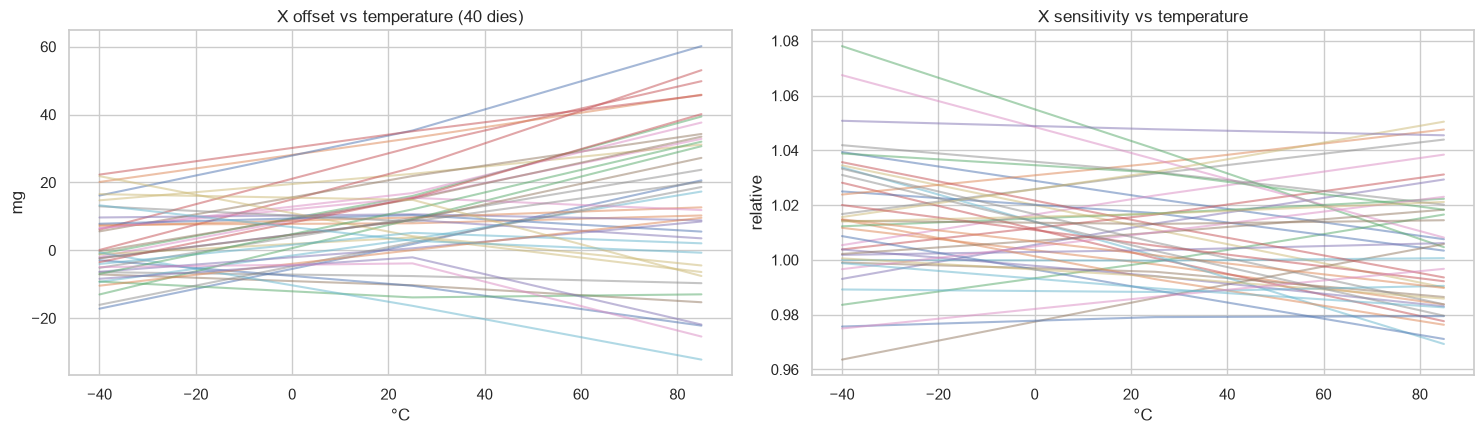

In [5]:
s = sensor.sample(40, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for _, d in s.iterrows():
    ax[0].plot([-40, 25, 85], [d.offset_x_m40C_mg, d.offset_x_25C_mg, d.offset_x_85C_mg], alpha=0.5)
    ax[1].plot([-40, 25, 85], [d.sens_x_m40C_rel, d.sens_x_25C_rel, d.sens_x_85C_rel], alpha=0.5)
ax[0].set(title="X offset vs temperature (40 dies)", xlabel="°C", ylabel="mg")
ax[1].set(title="X sensitivity vs temperature", xlabel="°C", ylabel="relative")
plt.tight_layout(); plt.show()

## 1.3 What predicts the coefficients?
Correlation of the 25 °C features with the three targets. Strong links mean the targets can be predicted without the hot and cold tests.

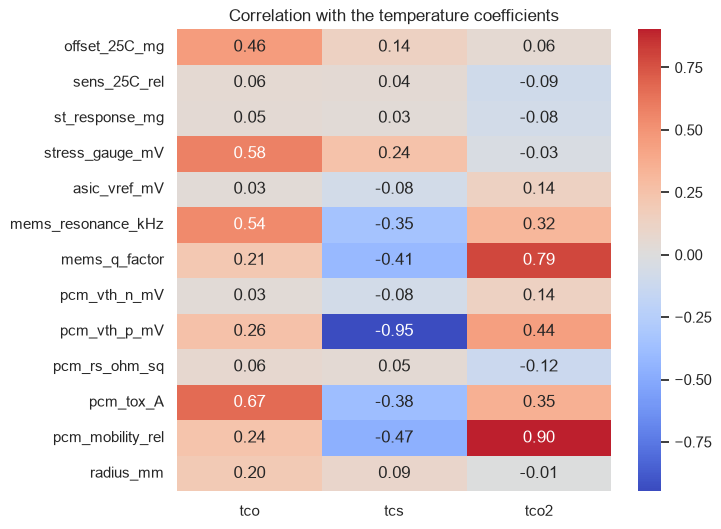

In [6]:
FEATS_25 = ["offset_25C_mg", "sens_25C_rel", "st_response_mg", "stress_gauge_mV", "asic_vref_mV",
            "mems_resonance_kHz", "mems_q_factor"] + PCM + ["radius_mm"]
plt.figure(figsize=(7, 6))
sns.heatmap(long[FEATS_25 + ["tco", "tcs", "tco2"]].corr().loc[FEATS_25, ["tco", "tcs", "tco2"]],
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation with the temperature coefficients"); plt.show()

## 1.4 Package stress drives several effects
The on-chip stress gauge relates to the offset, the temperature coefficient and the solder-reflow shift. ACC-16G (LGA12 package) sees more stress.

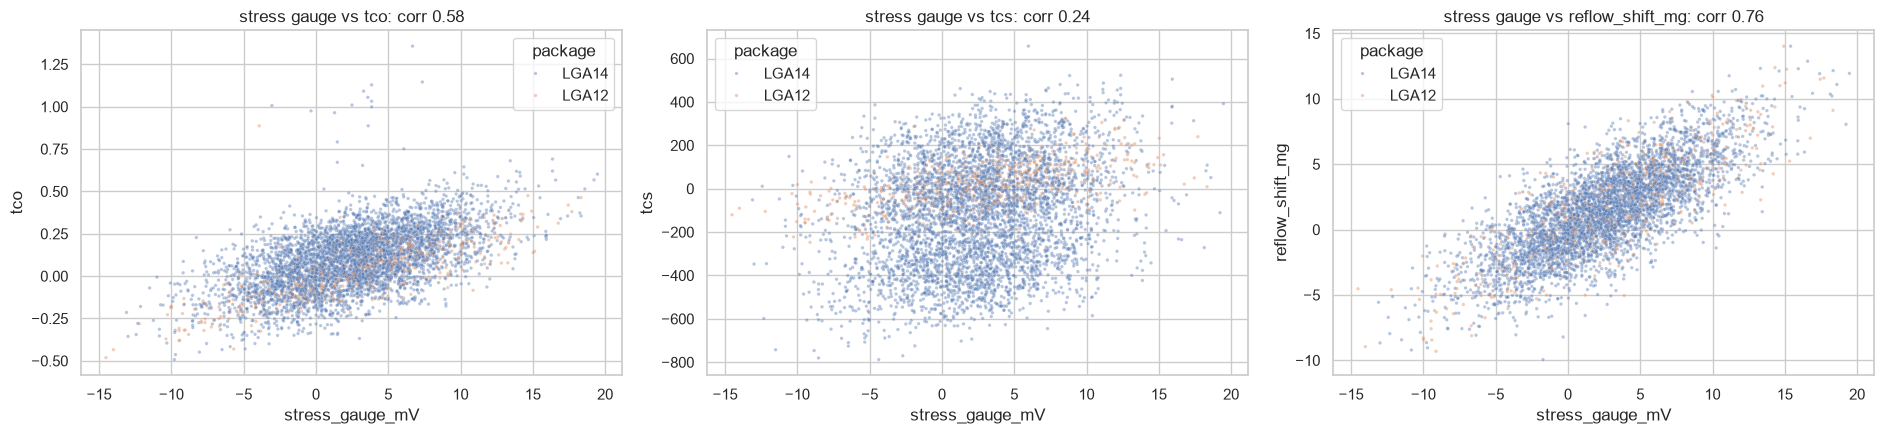

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(19, 4.5))
smp = long.sample(5000, random_state=SEED)
for a, y in zip(ax, ["tco", "tcs", "reflow_shift_mg"]):
    sns.scatterplot(data=smp, x="stress_gauge_mV", y=y, hue="package", s=6, alpha=0.4, ax=a)
    a.set_title(f"stress gauge vs {y}: corr {long.stress_gauge_mV.corr(long[y]):.2f}")
plt.tight_layout(); plt.show()

# Part 2: Train/test split
- **Training:** *characterized* ACC-2G dies from training wafers. These are the only dies that have hot and cold data in production.
- **Test:** *non-characterized* ACC-2G dies from **held-out wafers**. These are the dies the AI must calibrate. Their true hot and cold values exist only because the data is synthetic, and we use them **only to score**.
- ACC-8G and ACC-16G are kept for the transfer test (task E).

In [8]:
base = long[long.derivative == "ACC-2G"]
dies = base.drop_duplicates("die_id")
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(dies, groups=dies.wafer_id))
test_wafers = set(dies.iloc[te_idx].wafer_id)
train = base[~base.wafer_id.isin(test_wafers) & base.characterized_3temp].reset_index(drop=True)
test = base[base.wafer_id.isin(test_wafers) & ~base.characterized_3temp].reset_index(drop=True)
others = long[long.derivative != "ACC-2G"].reset_index(drop=True)
print(f"Train: {train.die_id.nunique()} characterized dies ({len(train)} axis rows), {train.wafer_id.nunique()} wafers")
print(f"Test : {test.die_id.nunique()} production dies ({len(test)} axis rows), {test.wafer_id.nunique()} held-out wafers")

Train: 1212 characterized dies (3636 axis rows), 11 wafers
Test : 1790 production dies (5370 axis rows), 4 held-out wafers


# Part 3, Task A (main): temperature coefficients from 25 °C

## 3.1 How we judge a calibration
The predicted coefficients give the predicted offset and sensitivity at −40 and 85 °C:
- offset(T) = offset₂₅ + TCO·ΔT + TCO2·ΔT²
- sens(T) = sens₂₅·(1 + TCS·10⁻⁶·ΔT)

We compare these with the **measured** values at −40 and 85 °C.

| Metric | Meaning |
|---|---|
| R² of TCO / TCS / TCO2 | How well each coefficient is predicted |
| RMS offset error at −40 / 85 °C (mg) | Average leftover offset error after calibration |
| RMS sensitivity error at 85 °C (%) | Leftover sensitivity error |
| **Spec pass %** | Axis meets **±10 mg offset and ±0.5% sensitivity at both −40 and 85 °C** (an example spec for this study) |

Two reference points:
- **Fleet average:** the classic single-insertion method; every die gets the average coefficients of the characterized dies.
- **Perfect coefficients:** the true values. This is the best possible result, limited only by measurement noise.

In [9]:
OFF_SPEC, SENS_SPEC = 10.0, 0.5   # mg, %
TARGETS = ["tco", "tcs", "tco2"]

def temp_eval(name, data, tco, tcs, tco2, off_spec=None, sens_spec=None):
    off_spec, sens_spec = off_spec or OFF_SPEC, sens_spec or SENS_SPEC
    out = {"model": name}
    for c, p in zip(TARGETS, [tco, tcs, tco2]):
        out[f"R2_{c}"] = r2_score(data[c], p) if np.ndim(p) else np.nan
    ok = np.ones(len(data), bool)
    for T, s in [(-40, "m40C"), (85, "85C")]:
        dT = T - 25
        off_err = data[f"offset_{s}_mg"] - (data.offset_25C_mg + tco * dT + tco2 * dT ** 2)
        sens_err = (data[f"sens_{s}_rel"] / (data.sens_25C_rel * (1 + tcs * 1e-6 * dT)) - 1) * 100
        out[f"RMS_off_{s}_mg"] = np.sqrt((off_err ** 2).mean())
        out[f"RMS_sens_{s}_%"] = np.sqrt((sens_err ** 2).mean())
        ok &= (np.abs(off_err) <= off_spec).values & (np.abs(sens_err) <= sens_spec).values
    out["spec_pass_%"] = ok.mean() * 100
    return out

zeros = np.zeros(len(test))
results = [temp_eval("No temp. compensation", test, zeros, zeros, zeros),
           temp_eval("Fleet average (classic 1-insertion)", test,
                     *(np.full(len(test), train[c].mean()) for c in TARGETS)),
           temp_eval("Perfect coefficients (noise floor)", test, *(test[c].values for c in TARGETS))]
pd.DataFrame(results).round(3)

,model,R2_tco,R2_tcs,R2_tco2,RMS_off_m40C_mg,RMS_sens_m40C_%,RMS_off_85C_mg,RMS_sens_85C_%,spec_pass_%
0,No temp. compensation,-1.585,-3.354,-0.004,16.981,1.956,16.329,1.806,1.546
1,Fleet average (classic 1-insertion),-0.652,-0.614,-0.054,14.254,1.185,12.844,1.114,9.646
2,Perfect coefficients (noise floor),1.000,1.000,1.000,2.141,0.137,2.118,0.140,99.888


## 3.2 Train the ML models
The same model families as notebooks 01 and 02, with one model per coefficient (TCO, TCS, TCO2).
Features: the axis's own 25 °C offset, sensitivity and self-test response, plus the die's stress gauge, ASIC reference, MEMS resonance and Q factor, PCM and position.

In [10]:
BASE_FEATS = ["axis", "offset_25C_mg", "sens_25C_rel", "st_response_mg", "stress_gauge_mV", "asic_vref_mV",
              "mems_resonance_kHz", "mems_q_factor"] + PCM + POS

def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=15, random_state=SEED, verbose=-1),
        "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                                                            early_stopping=True, random_state=SEED)),
    }

def fit_predict(name, feats, tr, te_sets):
    models = {c: make_models()[name].fit(tr[feats], tr[c]) for c in TARGETS}
    return models, [[models[c].predict(te[feats]) for c in TARGETS] for te in te_sets]

fitted = {}
for name in make_models():
    models, [preds] = fit_predict(name, BASE_FEATS, train, [test])
    fitted[name] = models
    results.append(temp_eval(name, test, *preds))
res = pd.DataFrame(results)
show = ["model", "R2_tco", "R2_tcs", "R2_tco2", "RMS_off_m40C_mg", "RMS_off_85C_mg", "RMS_sens_85C_%", "spec_pass_%"]
print(res[show].sort_values("spec_pass_%", ascending=False).round(3).to_string(index=False))

                              model  R2_tco  R2_tcs  R2_tco2  RMS_off_m40C_mg  RMS_off_85C_mg  RMS_sens_85C_%  spec_pass_%
 Perfect coefficients (noise floor)   1.000   1.000    1.000            2.141           2.118           0.140       99.888
                              Ridge   0.800   0.852    0.531            5.497           5.310           0.363       67.691
                           LightGBM   0.820   0.831    0.504            5.328           5.099           0.383       64.898
                            XGBoost   0.811   0.828    0.520            5.437           5.157           0.387       64.600
                       RandomForest   0.771   0.829    0.516            5.878           5.475           0.387       63.315
                                MLP   0.728   0.844    0.473            6.192           5.938           0.371       62.328
Fleet average (classic 1-insertion)  -0.652  -0.614   -0.054           14.254          12.844           1.114        9.646
              No

## 3.3 Visual comparison

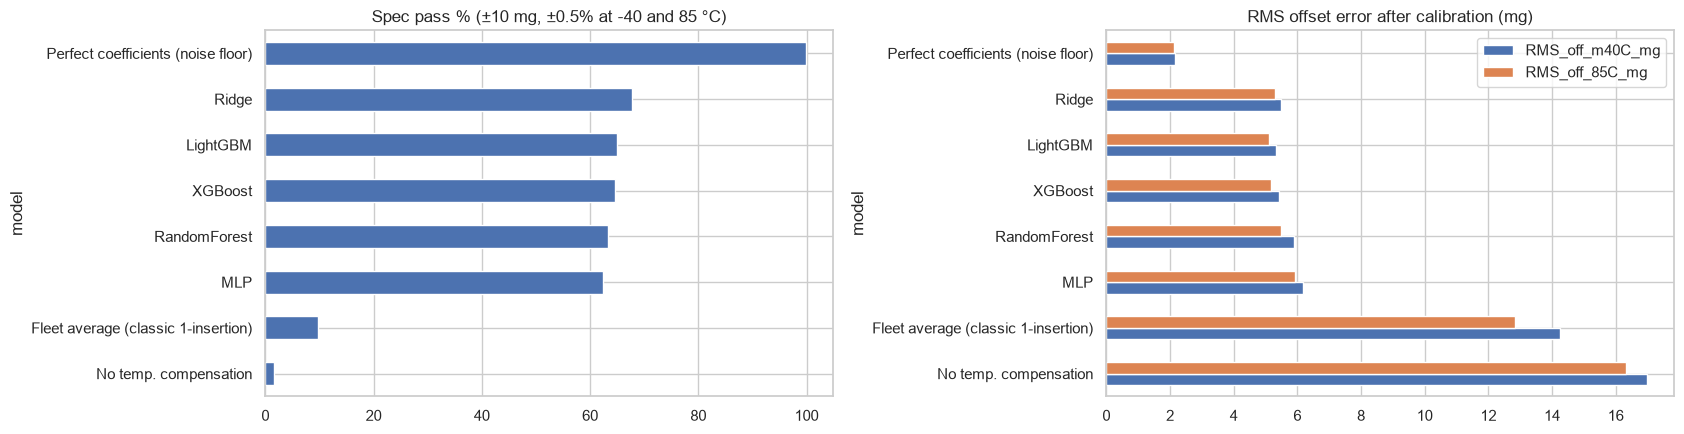

In [11]:
order = res.sort_values("spec_pass_%").model
fig, ax = plt.subplots(1, 2, figsize=(17, 4.5))
res.set_index("model").loc[order, "spec_pass_%"].plot.barh(ax=ax[0], color="#4c72b0")
ax[0].set_title(f"Spec pass % (±{OFF_SPEC:.0f} mg, ±{SENS_SPEC}% at -40 and 85 °C)")
res.set_index("model").loc[order, ["RMS_off_m40C_mg", "RMS_off_85C_mg"]].plot.barh(ax=ax[1])
ax[1].set_title("RMS offset error after calibration (mg)")
plt.tight_layout(); plt.show()

## 3.4 How strict can the spec be?
Pass rate across a range of offset limits. The gap between the best ML model and the noise floor is what is left to gain.

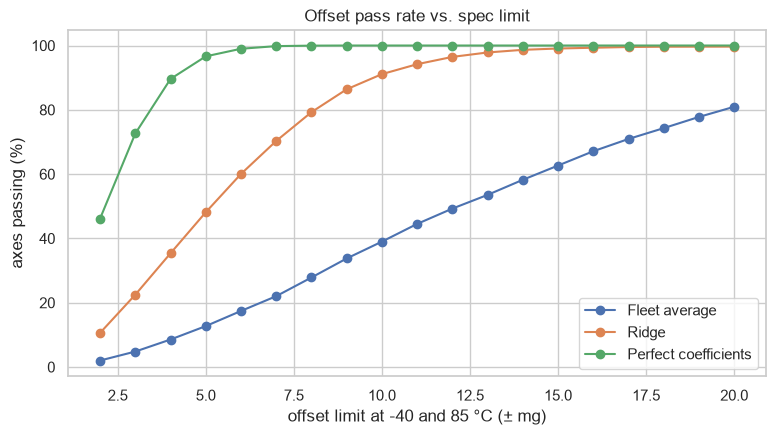

In [12]:
best_A = res[~res.model.str.contains("Perfect|No temp|Fleet")].sort_values("spec_pass_%").iloc[-1].model
lims = np.arange(2, 21, 1)
def offset_errors(tco, tco2):
    return np.maximum(*[np.abs(test[f"offset_{s}_mg"] - (test.offset_25C_mg + tco * (T - 25) + tco2 * (T - 25) ** 2))
                        for T, s in [(-40, "m40C"), (85, "85C")]])
curves = {"Fleet average": offset_errors(train.tco.mean(), train.tco2.mean()),
          best_A: offset_errors(*(fitted[best_A][c].predict(test[BASE_FEATS]) for c in ["tco", "tco2"])),
          "Perfect coefficients": offset_errors(test.tco, test.tco2)}
plt.figure(figsize=(9, 4.5))
for k, e in curves.items():
    plt.plot(lims, [(e <= l).mean() * 100 for l in lims], marker="o", label=k)
plt.xlabel("offset limit at -40 and 85 °C (± mg)"); plt.ylabel("axes passing (%)")
plt.title("Offset pass rate vs. spec limit"); plt.legend(); plt.show()

# Part 4, Task B: does the calibration fit into the OTP codes?
The chip stores each coefficient as an **8-bit signed code** (−128 to +127):
- TCO: 0.01 mg/°C per step
- TCS: 5 ppm/°C per step

We check that the predicted coefficients fit the code range (no clipping), and that the rounding error of the code is **much smaller** than the prediction error.

In [13]:
tco_p, tcs_p = (fitted[best_A][c].predict(test[BASE_FEATS]) for c in ["tco", "tcs"])
rows = []
for c, p, step, col in [("TCO", tco_p, 0.01, "cal_tco_code"), ("TCS", tcs_p, 5, "cal_tcs_code")]:
    raw_code = np.round(-p / step)
    code_ = np.clip(raw_code, -128, 127)
    rows.append({"coefficient": c, "step": step, "codes_clipped_%": (raw_code != code_).mean() * 100,
                 "code_rounding_error (max)": step / 2,
                 "prediction_error (MAE)": mean_absolute_error(test[c.lower()], p),
                 "code MAE vs ideal (LSB)": np.abs(code_ - test[col]).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))

coefficient  step  codes_clipped_%  code_rounding_error (max)  prediction_error (MAE)  code MAE vs ideal (LSB)
        TCO  0.01              0.0                      0.005                  0.0537                   5.3609
        TCS  5.00              0.0                      2.500                 44.1882                   8.8443


# Part 5, Task C: solder-reflow offset shift
When the customer solders the part onto a board, the offset shifts. If the shift is predicted at test, the calibration can **pre-compensate** for it.
Baselines: no compensation, and the average shift.

In [14]:
RF_FEATS = BASE_FEATS
rows = [{"method": "No compensation", "RMS_residual_mg": np.sqrt((test.reflow_shift_mg ** 2).mean()), "R2": np.nan},
        {"method": "Average shift", "RMS_residual_mg": np.sqrt(((test.reflow_shift_mg - train.reflow_shift_mg.mean()) ** 2).mean()),
         "R2": 0.0}]
reflow_models = {}
for name in ["Ridge", "RandomForest", "LightGBM"]:
    m = make_models()[name].fit(train[RF_FEATS], train.reflow_shift_mg); p = m.predict(test[RF_FEATS])
    reflow_models[name] = m
    rows.append({"method": name, "RMS_residual_mg": np.sqrt(((test.reflow_shift_mg - p) ** 2).mean()),
                 "R2": r2_score(test.reflow_shift_mg, p)})
reflow_res = pd.DataFrame(rows)
print(reflow_res.round(3).to_string(index=False))

         method  RMS_residual_mg    R2
No compensation            3.564   NaN
  Average shift            3.260 0.000
          Ridge            2.115 0.579
   RandomForest            2.190 0.548
       LightGBM            2.193 0.547


# Part 6, Task D: latent defect screening at 25 °C
About 0.3% of dies are latent defects. Their hidden fault changes the MEMS structure: a lower resonance frequency, and a larger temperature drift that would show only at hot or cold.
- **Rule:** resonance more than 6% below its wafer's median.
- **Isolation Forest:** unsupervised, on several 25 °C measurements.

Checked per die on all ACC dies.

Latent defects: 35 of 11060 dies

                                 method  flagged_%  recall_%  precision_%  ROC_AUC
Rule: resonance > 6% below wafer median       0.34     97.14        89.47     1.00
               IsolationForest top 0.5%       0.51      0.00         0.00     0.89
                 IsolationForest top 1%       1.00      2.86         0.90     0.89


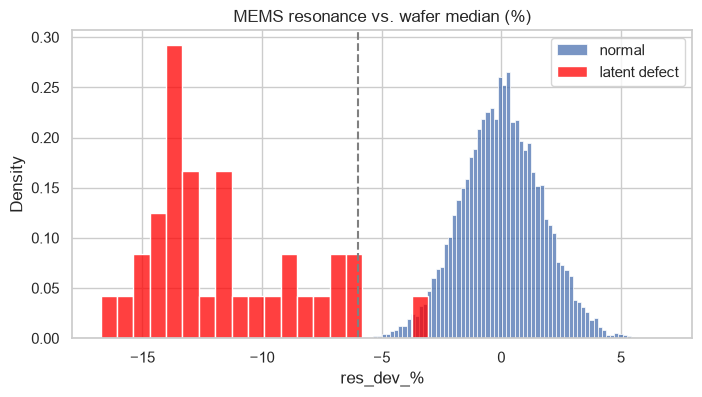

In [15]:
d = sensor.copy()
d["res_dev_%"] = (d.mems_resonance_kHz / d.groupby("wafer_id").mems_resonance_kHz.transform("median") - 1) * 100
d["offset_mean_25C"] = d[[f"offset_{a}_25C_mg" for a in "xyz"]].mean(axis=1)
y = d.latent_defect.values
ANOM = ["res_dev_%", "mems_q_factor", "stress_gauge_mV", "offset_mean_25C", "asic_vref_mV"] + \
       [f"st_response_{a}_mg" for a in "xyz"]

def report(name, flag, score=None):
    tp = (flag & y).sum()
    return {"method": name, "flagged_%": flag.mean() * 100, "recall_%": tp / y.sum() * 100,
            "precision_%": tp / max(flag.sum(), 1) * 100,
            "ROC_AUC": roc_auc_score(y, score) if score is not None else np.nan}

Xs = StandardScaler().fit_transform(d[ANOM])
score = -IsolationForest(n_estimators=300, random_state=SEED).fit(Xs).score_samples(Xs)
rows = [report("Rule: resonance > 6% below wafer median", (d["res_dev_%"] < -6).values, -d["res_dev_%"].values),
        report("IsolationForest top 0.5%", score >= np.quantile(score, 0.995), score),
        report("IsolationForest top 1%", score >= np.quantile(score, 0.99), score)]
print(f"Latent defects: {y.sum()} of {len(y)} dies\n")
print(pd.DataFrame(rows).round(2).to_string(index=False))

plt.figure(figsize=(8, 4))
sns.histplot(d.loc[~d.latent_defect, "res_dev_%"], bins=80, stat="density", label="normal")
sns.histplot(d.loc[d.latent_defect, "res_dev_%"], bins=20, stat="density", color="red", label="latent defect")
plt.axvline(-6, ls="--", color="grey"); plt.legend(); plt.title("MEMS resonance vs. wafer median (%)"); plt.show()

# Part 7: Can task A be optimized?

## 7.1 Feature engineering
Physics: package stress drives the offset, TCO and TCS on **all three axes**. Each axis's 25 °C offset is a noisy reading of that same stress, so averaging the three axes gives a cleaner estimate.

New features:
- `offset_25C_mean3`: the average 25 °C offset over the 3 axes
- `sens_25C_mean3`: the average 25 °C sensitivity over the 3 axes
- `is_lga12`: package flag (ACC-16G has more stress), which helps the transfer test

In [16]:
def add_features(df):
    df = df.copy()
    g = df.groupby("die_id")
    df["offset_25C_mean3"] = g.offset_25C_mg.transform("mean")
    df["sens_25C_mean3"] = g.sens_25C_rel.transform("mean")
    df["is_lga12"] = (df.package == "LGA12").astype(int)
    return df

train_fe, test_fe, others_fe = add_features(train), add_features(test), add_features(others)
FE_FEATS = BASE_FEATS + ["offset_25C_mean3", "sens_25C_mean3", "is_lga12"]
fe_results = []
for name in make_models():
    models, [preds] = fit_predict(name, FE_FEATS, train_fe, [test_fe])
    fitted[name + " +FE"] = models
    fe_results.append(temp_eval(name + " +FE", test_fe, *preds))
fe_res = pd.DataFrame(fe_results)
cmp = res.merge(fe_res.assign(model=fe_res.model.str.replace(" +FE", "", regex=False)), on="model", suffixes=("", "_FE"))
print(cmp[["model", "R2_tco", "R2_tco_FE", "R2_tcs", "R2_tcs_FE", "spec_pass_%", "spec_pass_%_FE"]].round(3).to_string(index=False))

       model  R2_tco  R2_tco_FE  R2_tcs  R2_tcs_FE  spec_pass_%  spec_pass_%_FE
       Ridge   0.800      0.811   0.852      0.856       67.691          68.715
RandomForest   0.771      0.771   0.829      0.832       63.315          63.073
     XGBoost   0.811      0.815   0.828      0.809       64.600          62.328
    LightGBM   0.820      0.823   0.831      0.837       64.898          65.885
         MLP   0.728      0.737   0.844      0.847       62.328          59.851


## 7.2 Hyperparameter tuning
The two best models after feature engineering are tuned for each coefficient with RandomizedSearchCV and 4-fold **GroupKFold by wafer**.

In [17]:
GRIDS = {
    "Ridge": {"ridge__alpha": np.logspace(-3, 2, 20)},
    "RandomForest": {"n_estimators": [200, 400, 600], "max_depth": [None, 10, 16], "min_samples_leaf": [1, 3, 5, 10],
                     "max_features": [0.5, 0.7, 1.0]},
    "XGBoost": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 5, 6],
                "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5]},
    "LightGBM": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31],
                 "min_child_samples": [10, 20, 40], "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1],
                 "colsample_bytree": [0.6, 0.8, 1.0]},
    "MLP": {"mlpregressor__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32)],
            "mlpregressor__alpha": [1e-4, 1e-3, 1e-2, 1e-1], "mlpregressor__learning_rate_init": [1e-3, 3e-3]},
}
top2 = fe_res.sort_values("spec_pass_%", ascending=False).model.head(2).str.replace(" +FE", "", regex=False).tolist()
tuned_results = []
for name in top2:
    models = {}
    for c in TARGETS:
        s = RandomizedSearchCV(make_models()[name], GRIDS[name], n_iter=12, cv=GroupKFold(n_splits=4),
                               scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
        models[c] = s.fit(train_fe[FE_FEATS], train_fe[c], groups=train_fe.wafer_id).best_estimator_
    fitted[name + " +FE +tuned"] = models
    tuned_results.append(temp_eval(name + " +FE +tuned", test_fe, *(models[c].predict(test_fe[FE_FEATS]) for c in TARGETS)))
tuned_res = pd.DataFrame(tuned_results)
everything = pd.concat([res, fe_res, tuned_res], ignore_index=True)
print(everything[show].sort_values("spec_pass_%", ascending=False).round(3).to_string(index=False))

                              model  R2_tco  R2_tcs  R2_tco2  RMS_off_m40C_mg  RMS_off_85C_mg  RMS_sens_85C_%  spec_pass_%
 Perfect coefficients (noise floor)   1.000   1.000    1.000            2.141           2.118           0.140       99.888
                   Ridge +FE +tuned   0.811   0.856    0.531            5.431           5.174           0.359       69.330
                          Ridge +FE   0.811   0.856    0.531            5.434           5.164           0.359       68.715
                              Ridge   0.800   0.852    0.531            5.497           5.310           0.363       67.691
                LightGBM +FE +tuned   0.819   0.843    0.527            5.380           5.056           0.373       67.058
                       LightGBM +FE   0.823   0.837    0.510            5.350           5.040           0.378       65.885
                           LightGBM   0.820   0.831    0.504            5.328           5.099           0.383       64.898
                

# Part 8, Task E: transfer to ACC-8G and ACC-16G
The range derivatives use the same MEMS element and ASIC; ACC-16G also has a different package (LGA12).
- **Zero-shot:** the ACC-2G model used as is.
- **Fine-tuned:** the derivative's own characterized dies (its 20% sample) are added to the training data.

Scored on each derivative's non-characterized dies.

In [18]:
best_ml = everything[~everything.model.str.contains("Perfect|No temp|Fleet")].sort_values("spec_pass_%").iloc[-1].model
family = best_ml.split(" ")[0]
feats_of = lambda m: FE_FEATS if "+FE" in m else BASE_FEATS
rows = []
for dv in ["ACC-8G", "ACC-16G"]:
    part = others_fe[(others_fe.derivative == dv) & ~others_fe.characterized_3temp]
    own = others_fe[(others_fe.derivative == dv) & others_fe.characterized_3temp]
    rows.append({**temp_eval("Fleet average (own char. dies)", part, *(np.full(len(part), own[c].mean()) for c in TARGETS)),
                 "derivative": dv})
    rows.append({**temp_eval(f"{best_ml}, zero-shot", part, *(fitted[best_ml][c].predict(part[feats_of(best_ml)]) for c in TARGETS)),
                 "derivative": dv})
    _, [preds] = fit_predict(family, FE_FEATS, pd.concat([train_fe, own]), [part])
    rows.append({**temp_eval(f"{family} +FE, fine-tuned", part, *preds), "derivative": dv})
transfer = pd.DataFrame(rows)
print(transfer[["derivative"] + show].round(3).to_string(index=False))

derivative                          model  R2_tco  R2_tcs  R2_tco2  RMS_off_m40C_mg  RMS_off_85C_mg  RMS_sens_85C_%  spec_pass_%
    ACC-8G Fleet average (own char. dies)  -0.001  -0.004   -0.001           10.356           9.633           0.686       25.013
    ACC-8G    Ridge +FE +tuned, zero-shot   0.759   0.772    0.642            5.507           5.237           0.349       68.049
    ACC-8G          Ridge +FE, fine-tuned   0.762   0.775    0.642            5.504           5.198           0.347       68.653
   ACC-16G Fleet average (own char. dies)  -0.004  -0.015   -0.001           11.357          10.955           0.665       23.508
   ACC-16G    Ridge +FE +tuned, zero-shot   0.828   0.767    0.527            5.359           5.182           0.342       69.262
   ACC-16G          Ridge +FE, fine-tuned   0.826   0.769    0.528            5.380           5.191           0.341       69.410


# Part 9: Final selection, test-time saving and saving

## 9.1 Final model
Highest spec pass %; ties go to the simpler model.

In [19]:
FINAL = best_ml
print("Final model for TCO / TCS / TCO2:", FINAL)
print(everything[everything.model.isin(["Fleet average (classic 1-insertion)", FINAL, "Perfect coefficients (noise floor)"])][show]
      .round(3).to_string(index=False))

Final model for TCO / TCS / TCO2: Ridge +FE +tuned
                              model  R2_tco  R2_tcs  R2_tco2  RMS_off_m40C_mg  RMS_off_85C_mg  RMS_sens_85C_%  spec_pass_%
Fleet average (classic 1-insertion)  -0.652  -0.614   -0.054           14.254          12.844           1.114        9.646
 Perfect coefficients (noise floor)   1.000   1.000    1.000            2.141           2.118           0.140       99.888
                   Ridge +FE +tuned   0.811   0.856    0.531            5.431           5.174           0.359       69.330


## 9.2 Which spec can a single insertion meet?
A single 25 °C insertion can't match the 3-temperature test for every spec. This table shows the pass rate of the final model at several offset limits (sensitivity limit: ±0.5% and ±1%). It tells us **which product grades** can move to the single-insertion flow.

In [20]:
f_preds = [fitted[FINAL][c].predict(test_fe[feats_of(FINAL)]) for c in TARGETS]
fleet = [np.full(len(test_fe), train[c].mean()) for c in TARGETS]
rows = []
for sens_lim in [0.5, 1.0]:
    for lim in [5, 8, 10, 12, 15, 20]:
        rows.append({"sens_limit_%": sens_lim, "offset_limit_mg": lim,
                     "fleet_average_pass_%": temp_eval("", test_fe, *fleet, lim, sens_lim)["spec_pass_%"],
                     "AI_1_insertion_pass_%": temp_eval("", test_fe, *f_preds, lim, sens_lim)["spec_pass_%"],
                     "3_insertions_pass_%": temp_eval("", test_fe, *(test_fe[c].values for c in TARGETS), lim, sens_lim)["spec_pass_%"]})
grades = pd.DataFrame(rows)
print(grades.round(1).to_string(index=False))

 sens_limit_%  offset_limit_mg  fleet_average_pass_%  AI_1_insertion_pass_%  3_insertions_pass_%
          0.5                5                   3.1                   37.4                 96.5
          0.5                8                   6.8                   61.6                 99.9
          0.5               10                   9.6                   69.3                 99.9
          0.5               12                  11.9                   72.8                 99.9
          0.5               15                  14.8                   74.4                 99.9
          0.5               20                  18.8                   74.7                 99.9
          1.0                5                   6.5                   48.9                 96.6
          1.0                8                  14.3                   80.7                100.0
          1.0               10                  20.0                   91.2                100.0
          1.0               12

## 9.3 Test-time saving
Today: 3 insertions, about 7.2 s per die. AI flow: one 25 °C insertion for most dies. A small share keeps the full 3-temperature test to supply training data and monitor drift; we assume 5% here. The data's 20% was a characterization study, not a production rate.

In [21]:
conv = sensor.conv_test_time_s.mean()
one = conv / 3
for keep in [0.05, 0.20]:
    ai = (1 - keep) * one + keep * conv
    print(f"Keep {keep:.0%} on 3 temps: {conv:.2f} s -> {ai:.2f} s per die ({100 * (1 - ai / conv):.0f}% less), "
          f"insertions {3:.1f} -> {(1 - keep) * 1 + keep * 3:.2f}")

Keep 5% on 3 temps: 7.20 s -> 2.64 s per die (63% less), insertions 3.0 -> 1.10
Keep 20% on 3 temps: 7.20 s -> 3.36 s per die (53% less), insertions 3.0 -> 1.40


## 9.4 Save the models

In [22]:
bundle = {"coefficients": fitted[FINAL], "name": FINAL, "features": feats_of(FINAL), "add_features": "offset/sens mean over 3 axes, is_lga12",
          "reflow": reflow_models[reflow_res.iloc[2:].sort_values("RMS_residual_mg").iloc[0].method],
          "reflow_features": RF_FEATS, "spec": {"offset_mg": OFF_SPEC, "sens_pct": SENS_SPEC}}
joblib.dump(bundle, "sensor_models.joblib", compress=3)
print("Saved sensor_models.joblib:", round(os.path.getsize("sensor_models.joblib") / 1e3, 1), "KB")

Saved sensor_models.joblib: 2.5 KB


## 9.5 Use the models on one die (25 °C data only)

In [23]:
saved = joblib.load("sensor_models.joblib")
die = test_fe[test_fe.die_id == test_fe.die_id.iloc[0]]
for _, r in die.iterrows():
    x = r[saved["features"]].to_frame().T.astype(float)
    tco, tcs, tco2 = (saved["coefficients"][c].predict(x)[0] for c in TARGETS)
    print(f"axis {'xyz'[int(r.axis)]}: TCO {tco:+.3f} (true {r.tco:+.3f}) | TCS {tcs:+.0f} (true {r.tcs:+.0f}) ppm/°C | "
          f"predicted 85 °C offset {r.offset_25C_mg + tco * 60 + tco2 * 3600:+.1f} mg (measured {r.offset_85C_mg:+.1f})")

axis x: TCO +0.164 (true +0.139) | TCS -223 (true -195) ppm/°C | predicted 85 °C offset -16.4 mg (measured -16.5)
axis y: TCO +0.185 (true +0.108) | TCS -223 (true -286) ppm/°C | predicted 85 °C offset -12.5 mg (measured -21.4)
axis z: TCO +0.200 (true +0.209) | TCS -221 (true -194) ppm/°C | predicted 85 °C offset -17.5 mg (measured -16.0)


# Part 10: Would deep learning, GANs or reinforcement learning help here?

- **Deep learning (MLP):** it ranked **last among the ML models** (62% spec pass before tuning, vs. 68–69% for Ridge). With only ~1,200 characterized dies and near-linear physics, a neural network has nothing extra to find.
- **The real limit is noise, not the model:** Ridge, LightGBM and XGBoost all reach R² ≈ 0.80–0.86 for TCO and TCS. Each die carries random variation that no 25 °C measurement can see. A bigger model can't predict something that was never measured.
- **GAN:** synthetic dies would not add information about that unseen variation, and fake training data is unacceptable for automotive or medical calibration (traceability).
- **RNN / LSTM:** not applicable. Each die is a single row, not a sequence.
- **Reinforcement learning:** could *decide which dies to send to the 3-temperature test* (a sampling policy). That's a possible future step, but a simple rule (keep a fixed 5% sample plus any flagged dies) does the job and is easier to certify.
- **Anomaly detection:** Isolation Forest failed (0–3% recall). The simple physics rule (resonance more than 6% below the wafer median) caught 97% of latent defects at 89% precision.

# Part 11: Summary: what was chosen and why

| Task | Chosen method | Result | Why |
|---|---|---|---|
| **A. TCO / TCS / TCO2 from 25 °C only** | **Ridge regression** (+ 3-axis features, tuned) | R² 0.81 (TCO) and 0.86 (TCS); RMS offset error at 85 °C **12.8 → 5.2 mg** vs. the fleet average | Best of 5 models; near-linear physics; tiny model (2.5 KB) and fully explainable |
| B. OTP calibration codes | 8-bit codes, as designed | 0% clipped; code rounding (0.005 mg/°C) is ~10× smaller than the prediction error | The codes don't limit accuracy |
| C. Solder-reflow shift | Ridge | RMS residual 3.6 → 2.1 mg (R² 0.58) | Stress gauge and offsets predict the package stress |
| D. Latent defects | Physics rule on MEMS resonance | 97% recall, 89% precision | Simple and exact; Isolation Forest failed |
| E. ACC-8G, ACC-16G | Same ACC-2G model, no retraining | 68–69% spec pass, the same as the base product | Fine-tuning added under 1 point |

**Which grades move to the single-insertion flow (from 9.2):**

| Spec (offset / sensitivity) | Fleet average | AI, 1 insertion | 3 insertions |
|---|---|---|---|
| ±10 mg / ±0.5% (tight) | 9.6% | 69.3% | 99.9% |
| ±12 mg / ±1% | 25.4% | **96.0%** | 100% |
| ±15 mg / ±1% (consumer-type) | 31.7% | **98.0%** | 100% |

- **Recommendation:** use the AI single-insertion flow for looser grades (±12–15 mg, ±1%), and keep the 3-temperature test for tight automotive or medical grades. The binding limit is sensitivity at ±0.5%.
- **Business result:** for the grades that move, test time drops from **7.2 s to 2.6 s per die (−63%)**, keeping 5% of dies on the 3-temperature test for monitoring and retraining.
- **Honest note:** the brief's idea of "1 insertion instead of 3" works **for some grades, not all**. The data shows exactly where the line is.

## Project summary prompt (copy and paste)
```text
Notebook 03 (Sensor) of my AI-Optimized Trim & Fuse project. Data: sensor_calibration.csv,
11,060 3-axis MEMS accelerometers (ACC-2G base, ACC-8G, ACC-16G). Today every die is tested at
-40/25/85 C (3 insertions, 7.2 s). Goal: test only at 25 C and predict the temperature
coefficients (TCO, TCS, TCO2). Stacked the 3 axes into one table (one model for all axes).
Trained on the 20% characterized dies of training wafers; tested on production dies of
held-out wafers. Compared fleet average, Ridge, Random Forest, XGBoost, LightGBM and MLP,
plus feature engineering (3-axis averages) and GroupKFold tuning. Ridge won: R2 0.81 / 0.86,
85 C offset error 12.8 -> 5.2 mg. At a +/-15 mg, +/-1% spec, 98% of axes pass with 1 insertion
(fleet average: 32%); at the tight +/-10 mg, +/-0.5% spec only 69% do, so tight automotive grades
keep 3 insertions. Test time 7.2 -> 2.6 s per die (-63%) for the grades that move. Also:
reflow shift prediction (3.6 -> 2.1 mg), latent-defect rule on MEMS resonance (97% recall),
transfer to 8G/16G with no retraining. MLP, GAN, RNN and RL judged not useful.
```